# Fresh Eyes on CMIP Data Workshop 2026: Applications of CMIP6 data.
## Create climate stripes using historical data (1979-2024) by downloading CMIP6 data with intake-ESM

### Import all relevant modules

In [1]:
import intake
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import matplotlib as mpl
from matplotlib.colors import ListedColormap
import numpy as np
import xarray as xr
import warnings
warnings.filterwarnings("ignore")

### Let's search again the dataset using intake.

In [2]:
cat_url = "https://storage.googleapis.com/cmip6/pangeo-cmip6.json"
col = intake.open_esm_datastore(cat_url)
col

,unique
activity_id,18
institution_id,36
source_id,88
experiment_id,170
member_id,657
table_id,37
variable_id,700
grid_label,10
zstore,514818
dcpp_init_year,61


### We will search for the same data as before. Note, we need to download additional file since CMIP6 historical data ends in 2014. We will choose the ssp585 scenario to mimic historical data from 2015-2024.

In [3]:
cat= col.search(
    table_id='Amon',
    institution_id="CSIRO-ARCCSS",
    experiment_id=['historical','ssp585'],
    source_id='ACCESS-CM2',
    variable_id='tas',
    member_id='r1i1p1f1',
    grid_label='gn')
cat.df

,activity_id,institution_id,source_id,experiment_id,member_id,table_id,variable_id,grid_label,zstore,dcpp_init_year,version
0,CMIP,CSIRO-ARCCSS,ACCESS-CM2,historical,r1i1p1f1,Amon,tas,gn,gs://cmip6/CMIP6/CMIP/CSIRO-ARCCSS/ACCESS-CM2/...,<NA>,20191108
1,ScenarioMIP,CSIRO-ARCCSS,ACCESS-CM2,ssp585,r1i1p1f1,Amon,tas,gn,gs://cmip6/CMIP6/ScenarioMIP/CSIRO-ARCCSS/ACCE...,<NA>,20210317


### Intake-ESM automatically opens the dataset using xarray.

### Lets open both datasets.

In [4]:
dset_dict = cat.to_dataset_dict(
    xarray_open_kwargs={'chunks': {}},
    storage_options={'token': 'anon'},
    threaded=False
)

print(list(dset_dict.keys()))



--> The keys in the returned dictionary of datasets are constructed as follows:
	'activity_id.institution_id.source_id.experiment_id.table_id.grid_label'


<div><progress max="2" value="2"></progress> 100.00% [2/2 00:02&lt;00:00]</div>

['CMIP.CSIRO-ARCCSS.ACCESS-CM2.historical.Amon.gn', 'ScenarioMIP.CSIRO-ARCCSS.ACCESS-CM2.ssp585.Amon.gn']


### We can select both datasets

In [5]:

ds_hist = dset_dict[
    'CMIP.CSIRO-ARCCSS.ACCESS-CM2.historical.Amon.gn'
]
ds_hist



<xarray.Dataset> Size: 219MB
Dimensions:         (member_id: 1, dcpp_init_year: 1, time: 1980, lat: 144,
                     lon: 192, bnds: 2)
Coordinates:
  * member_id       (member_id) object 8B 'r1i1p1f1'
  * dcpp_init_year  (dcpp_init_year) float64 8B nan
  * time            (time) datetime64[ns] 16kB 1850-01-16T12:00:00 ... 2014-1...
  * lat             (lat) float64 1kB -89.38 -88.12 -86.88 ... 86.88 88.12 89.38
  * lon             (lon) float64 2kB 0.9375 2.812 4.688 ... 355.3 357.2 359.1
    lat_bnds        (lat, bnds) float64 2kB dask.array<chunksize=(144, 2), meta=np.ndarray>
    lon_bnds        (lon, bnds) float64 3kB dask.array<chunksize=(192, 2), meta=np.ndarray>
    time_bnds       (time, bnds) datetime64[ns] 32kB dask.array<chunksize=(1980, 2), meta=np.ndarray>
    height          float64 8B ...
Dimensions without coordinates: bnds
Data variables:
    tas             (member_id, dcpp_init_year, time, lat, lon) float32 219MB dask.array<chunksize=(1, 1, 668, 144, 192), meta=np.ndarray>
Attributes: (12/61)
    Conventions:                      CF-1.7 CMIP-6.2
    activity_id:                      CMIP
    branch_method:                    standard
    branch_time_in_child:             0.0
    branch_time_in_parent:            0.0
    cmor_version:                     3.4.0
    ...                               ...
    intake_esm_attrs:variable_id:     tas
    intake_esm_attrs:grid_label:      gn
    intake_esm_attrs:zstore:          gs://cmip6/CMIP6/CMIP/CSIRO-ARCCSS/ACCE...
    intake_esm_attrs:version:         20191108
    intake_esm_attrs:_data_format_:   zarr
    intake_esm_dataset_key:           CMIP.CSIRO-ARCCSS.ACCESS-CM2.historical...

In [6]:
ds_ssp585 = dset_dict[
    'ScenarioMIP.CSIRO-ARCCSS.ACCESS-CM2.ssp585.Amon.gn'
]
ds_ssp585

<xarray.Dataset> Size: 380MB
Dimensions:         (member_id: 1, dcpp_init_year: 1, time: 3432, lat: 144,
                     lon: 192, bnds: 2)
Coordinates:
  * member_id       (member_id) object 8B 'r1i1p1f1'
  * dcpp_init_year  (dcpp_init_year) float64 8B nan
  * time            (time) object 27kB 2015-01-16 12:00:00 ... 2300-12-16 12:...
  * lat             (lat) float64 1kB -89.38 -88.12 -86.88 ... 86.88 88.12 89.38
  * lon             (lon) float64 2kB 0.9375 2.812 4.688 ... 355.3 357.2 359.1
    lat_bnds        (lat, bnds) float64 2kB dask.array<chunksize=(144, 2), meta=np.ndarray>
    lon_bnds        (lon, bnds) float64 3kB dask.array<chunksize=(192, 2), meta=np.ndarray>
    time_bnds       (time, bnds) object 55kB dask.array<chunksize=(3432, 2), meta=np.ndarray>
    height          float64 8B ...
Dimensions without coordinates: bnds
Data variables:
    tas             (member_id, dcpp_init_year, time, lat, lon) float32 380MB dask.array<chunksize=(1, 1, 668, 144, 192), meta=np.ndarray>
Attributes: (12/63)
    Conventions:                      CF-1.7 CMIP-6.2
    activity_id:                      ScenarioMIP
    branch_method:                    standard
    branch_time_in_child:             60265.0
    branch_time_in_parent:            60265.0
    cmor_version:                     3.4.0
    ...                               ...
    intake_esm_attrs:variable_id:     tas
    intake_esm_attrs:grid_label:      gn
    intake_esm_attrs:zstore:          gs://cmip6/CMIP6/ScenarioMIP/CSIRO-ARCC...
    intake_esm_attrs:version:         20210317
    intake_esm_attrs:_data_format_:   zarr
    intake_esm_dataset_key:           ScenarioMIP.CSIRO-ARCCSS.ACCESS-CM2.ssp...

### Let's merge both dataset and select the historical period from 1979-2024

In [7]:
ds_hist = ds_hist.sel(time=slice("1979-01-01", "2014-12-31"))
ds_ssp585 = ds_ssp585.sel(time=slice("2015-01-01", "2024-12-31"))

# Convert to common datetime64[ns]
ds_hist = ds_hist.convert_calendar(
    "proleptic_gregorian",
    use_cftime=False
)

ds_ssp585 = ds_ssp585.convert_calendar(
    "proleptic_gregorian",
    use_cftime=False
)

ds_combined = xr.concat(
    [ds_hist[["tas"]], ds_ssp585[["tas"]]],
    dim="time",
    coords="minimal",
    compat="override",
    combine_attrs="override"
)

# Sort by time
ds_combined = ds_combined.sortby("time")

ds_combined

<xarray.Dataset> Size: 61MB
Dimensions:         (member_id: 1, dcpp_init_year: 1, time: 552, lat: 144,
                     lon: 192)
Coordinates:
  * member_id       (member_id) object 8B 'r1i1p1f1'
  * dcpp_init_year  (dcpp_init_year) float64 8B nan
  * time            (time) datetime64[ns] 4kB 1979-01-16T12:00:00 ... 2024-12...
  * lat             (lat) float64 1kB -89.38 -88.12 -86.88 ... 86.88 88.12 89.38
  * lon             (lon) float64 2kB 0.9375 2.812 4.688 ... 355.3 357.2 359.1
    height          float64 8B ...
Data variables:
    tas             (member_id, dcpp_init_year, time, lat, lon) float32 61MB dask.array<chunksize=(1, 1, 432, 144, 192), meta=np.ndarray>
Attributes: (12/61)
    Conventions:                      CF-1.7 CMIP-6.2
    activity_id:                      CMIP
    branch_method:                    standard
    branch_time_in_child:             0.0
    branch_time_in_parent:            0.0
    cmor_version:                     3.4.0
    ...                               ...
    intake_esm_attrs:variable_id:     tas
    intake_esm_attrs:grid_label:      gn
    intake_esm_attrs:zstore:          gs://cmip6/CMIP6/CMIP/CSIRO-ARCCSS/ACCE...
    intake_esm_attrs:version:         20191108
    intake_esm_attrs:_data_format_:   zarr
    intake_esm_dataset_key:           CMIP.CSIRO-ARCCSS.ACCESS-CM2.historical...

### Some examples of data processing

### Convert Temperature to °C

In [8]:
tas = ds_combined.tas - 273.15

### Calculate monthly climatology from reference period. Reference period is defined based on https://www.nature.com/articles/s43247-022-00498-3 (See Fig. 1a)

In [9]:
tas_ref = tas.sel(time=slice('1981-01-01', '2010-12-31'))

tas_clim = tas_ref.groupby('time.month').mean('time')

### Calculate monthly temperature anomalies relative to 1981–2010

In [10]:
tas_anom = tas.groupby('time.month') - tas_clim


### Quickly map the mean of temperature anomaly.

Text(0.5, 1.0, 'Near-Surface Air Temperature Anomalies, 1979-2024')

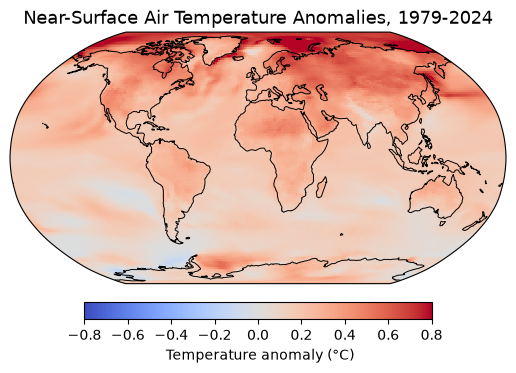

In [11]:
fig, axis = plt.subplots(1, 1, subplot_kw=dict(projection=ccrs.Robinson()))

vmin, vmax = -0.8, 0.8

tas_anom.mean("time").plot(
    ax=axis,
    transform=ccrs.PlateCarree(),
    cmap="coolwarm",
    vmin=vmin,
    vmax=vmax,
    cbar_kwargs={
        "orientation": "horizontal",
        "shrink": 0.7,
        "pad": 0.05,
        "label": " Temperature anomaly (°C)",
        "ticks": np.linspace(vmin, vmax, 9),
        "extend": "neither"
    }
)

axis.coastlines(linewidth=0.7)
axis.set_global()
axis.set_title("Near-Surface Air Temperature Anomalies, 1979-2024", fontsize=13)


### Lets now have a look closer at the Arctic region, 65-90 N

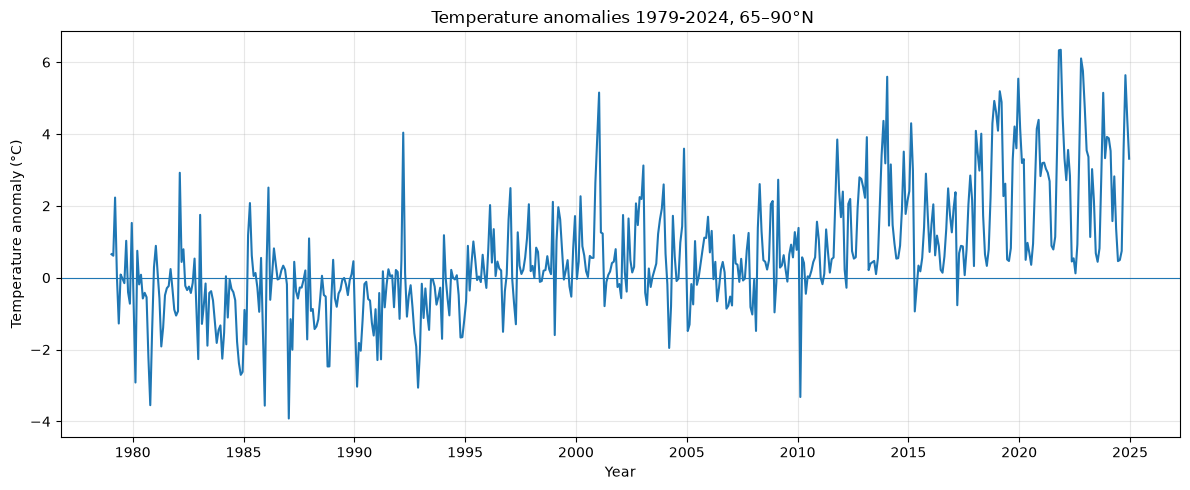

In [12]:
# Select regional mean 65–90°N
tas_65_90N = tas_anom.sel(lat=slice(65, 90)).mean(dim=['lat', 'lon'])


# Plot
plt.figure(figsize=(12, 5))

plt.plot(
    tas_65_90N.time,
    tas_65_90N.squeeze(),
    linewidth=1.5
)

plt.axhline(0, linewidth=0.8)

plt.xlabel('Year')
plt.ylabel('Temperature anomaly (°C)')
plt.title(' Temperature anomalies 1979-2024, 65–90°N')
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Let's transform the line plot to climate stripes.

Text(0.5, 1.0, 'Artic Warming Stripes 1979-2024, 65–90°N')

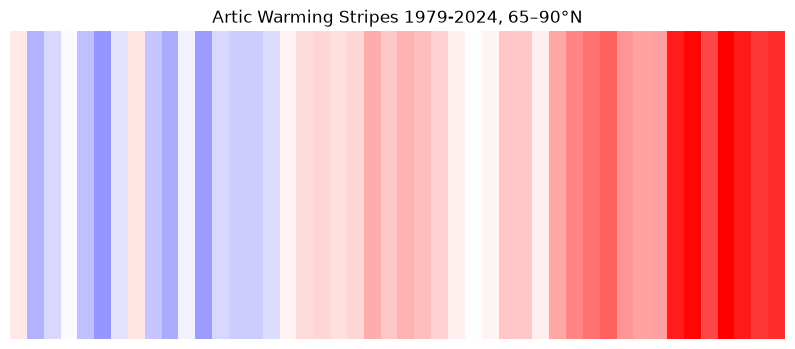

In [13]:
# 
tas_65_90N_yearly = tas_65_90N.groupby('time.year').mean('time')


temperature = tas_65_90N_yearly.squeeze() 


nx = len(temperature)
x = np.arange(len(temperature))
y = np.array([0, 1])
temperature = np.vstack([temperature, temperature])

cmap = 'bwr' 

limit = np.nanmax(np.abs(temperature))

norm = mpl.colors.Normalize(vmin=-limit,vmax=limit)

figure, axes = plt.subplots(figsize=(10, 4))
axes.pcolormesh(x, y, temperature, cmap=cmap, norm=norm, shading='auto')
axes.set_axis_off()
plt.title("Artic Warming Stripes 1979-2024, 65–90°N")